# Caracterización: abandonan vs. permanecen (obj. específico 2)

**Dueño/a:** Ianis · **Semana 2**

Regla: el notebook solo *muestra* resultados; la lógica vive en `src/churn/` para que se pueda probar.

In [2]:
import sys
sys.path.insert(0, '../src')

import pandas as pd
from churn.datos import cargar_limpio
from churn.caracterizacion import (
    tabla_numericas,
    tabla_categoricas,
    graficar_categoricas
)
df = cargar_limpio()

print(f"Total de clientes: {len(df)}")
df.head()

Total de clientes: 2850


,fila_original,fallas_llamada,quejas,meses_suscripcion,nivel_cobro,segundos_uso,frecuencia_llamadas,frecuencia_sms,numeros_distintos,plan_tarifa,estado,edad,valor_cliente,churn
0,1,8,0,38,0,4370,71,5,17,1,1,30,197.640,0
1,2,0,0,39,0,318,5,7,4,1,2,25,46.035,0
2,3,10,0,37,0,2453,60,359,24,1,1,30,1536.520,0
3,4,10,0,38,0,4198,66,1,35,1,1,15,240.020,0
4,5,3,0,38,0,2393,58,2,33,1,1,15,145.805,0


In [3]:
tabla_num = tabla_numericas(df)
display(tabla_num)

,variable,mediana_abandona,q1_abandona,q3_abandona,mediana_permanece,q1_permanece,q3_permanece,p_valor,efecto
0,segundos_uso,1256.500,438.000,2458.00,3596.50,1858.00000,6920.00000,1.843782e-82,-0.572678
1,valor_cliente,102.565,45.495,187.98,271.54,145.62875,862.59625,1.585944e-79,-0.562160
2,frecuencia_llamadas,29.000,7.000,46.75,64.00,33.00000,106.00000,7.228963e-72,-0.533697
3,numeros_distintos,11.000,3.250,20.00,24.00,13.00000,36.00000,2.413410e-54,-0.462055
4,frecuencia_sms,11.000,1.000,24.00,26.00,7.00000,133.00000,1.966711e-30,-0.340249
5,meses_suscripcion,35.000,31.000,37.00,35.00,29.00000,38.00000,7.770285e-02,-0.052452
6,fallas_llamada,6.000,1.000,12.00,6.00,2.00000,12.00000,4.331348e-01,-0.023205


In [4]:
tabla_cat = tabla_categoricas(df)
display(tabla_cat)

,variable,nivel,n,tasa_churn,p_valor
0,quejas,0,2620,0.097710,1.266294e-185
1,quejas,1,230,0.826087,1.266294e-185
2,nivel_cobro,0,1575,0.237460,9.999000e-05
3,nivel_cobro,1,559,0.075134,9.999000e-05
4,nivel_cobro,2,362,0.060773,9.999000e-05
5,nivel_cobro,3,192,0.036458,9.999000e-05
6,nivel_cobro,4,70,0.014286,9.999000e-05
7,nivel_cobro,5,30,0.000000,9.999000e-05
8,nivel_cobro,6,11,0.000000,9.999000e-05
9,nivel_cobro,7,12,0.000000,9.999000e-05


## Gráficos variables numéricas

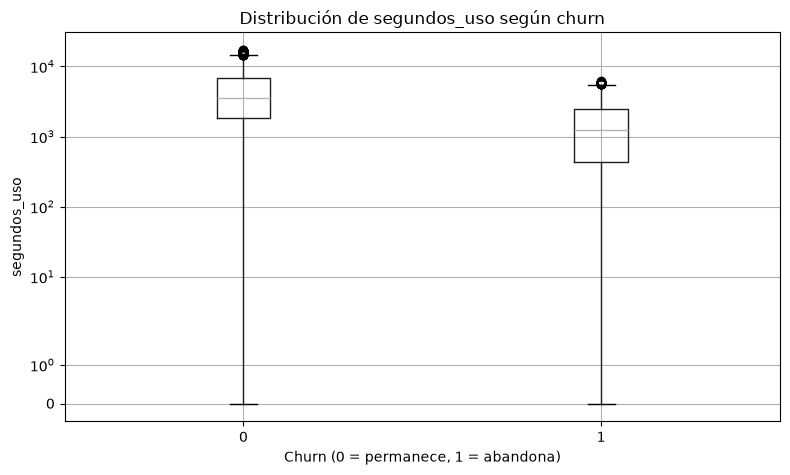

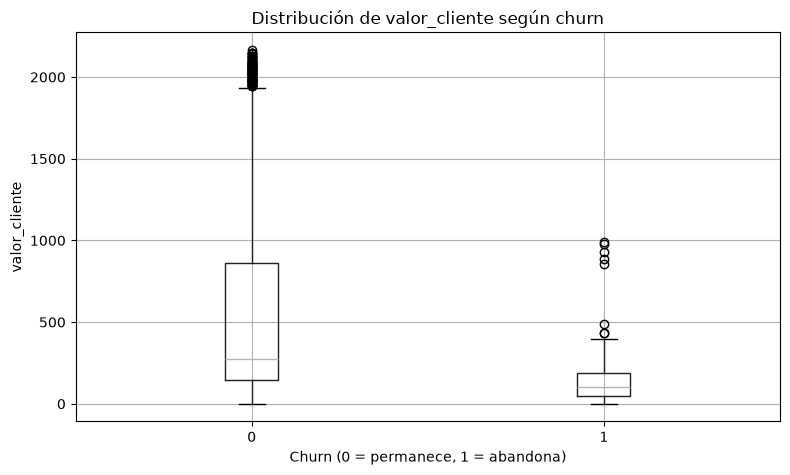

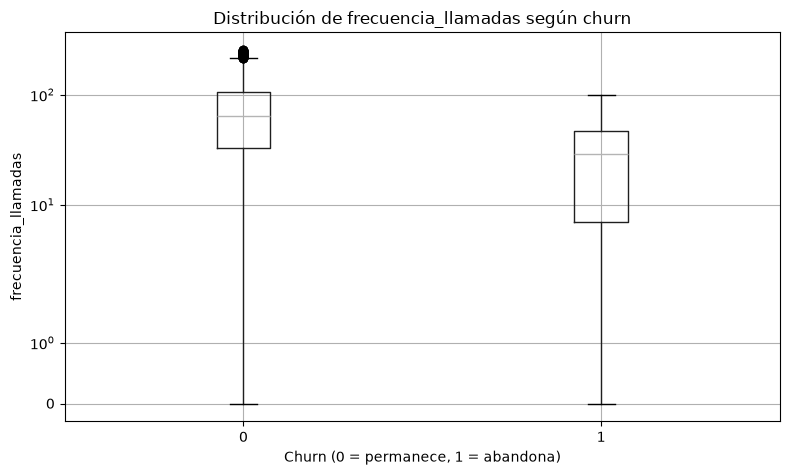

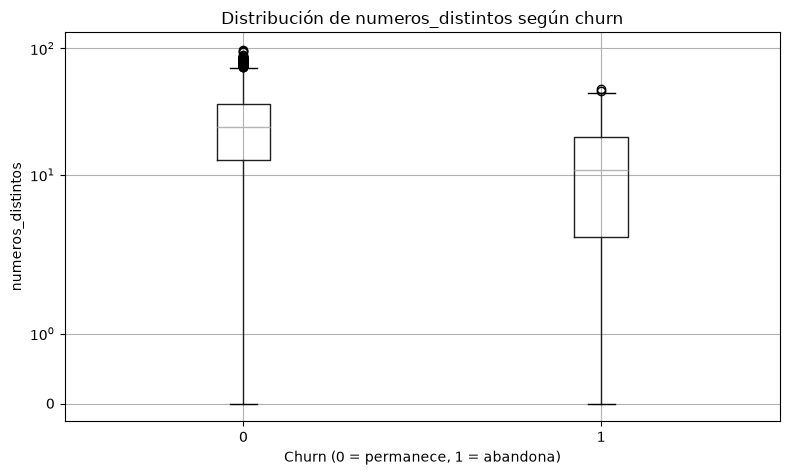

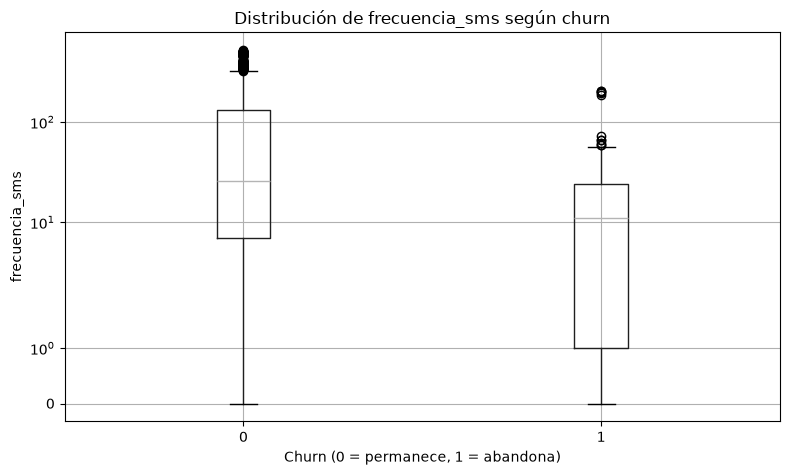

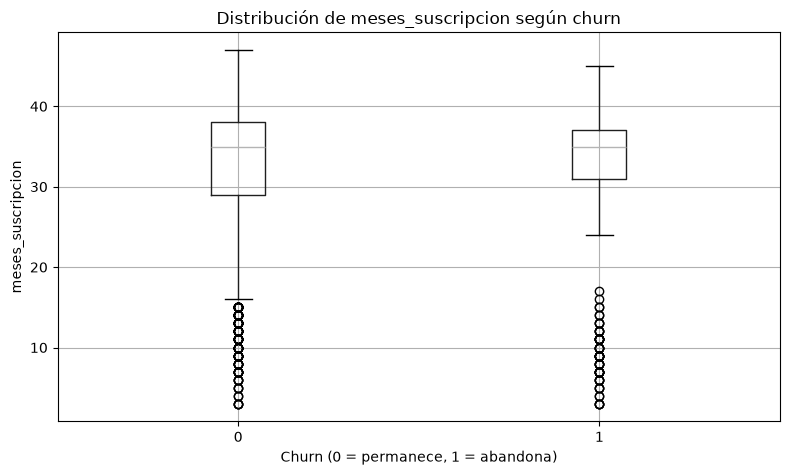

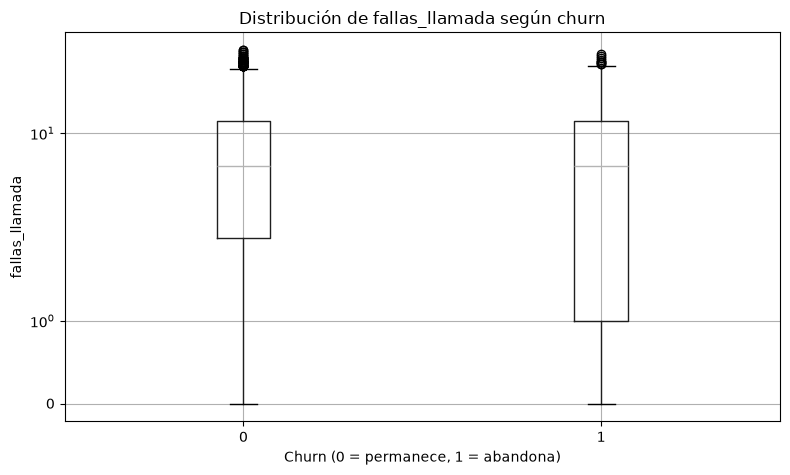

In [5]:
import matplotlib.pyplot as plt
from pathlib import Path

# Crear la carpeta para guardar las gráficas
carpeta = Path("../reports/figures")
carpeta.mkdir(parents=True, exist_ok=True)

variables = [
    "segundos_uso",
    "valor_cliente",
    "frecuencia_llamadas",
    "numeros_distintos",
    "frecuencia_sms",
    "meses_suscripcion",
    "fallas_llamada"
]

# Variables de uso que representaremos con escala logarítmica
variables_uso = [
    "segundos_uso",
    "frecuencia_llamadas",
    "numeros_distintos",
    "frecuencia_sms",
    "fallas_llamada"
]

for variable in variables:
    fig, ax = plt.subplots(figsize=(8, 5))

    df.boxplot(
        column=variable,
        by="churn",
        ax=ax
    )

    ax.set_title(f"Distribución de {variable} según churn")
    ax.set_xlabel("Churn (0 = permanece, 1 = abandona)")
    ax.set_ylabel(variable)

    if variable in variables_uso:
        ax.set_yscale("symlog")

    plt.suptitle("")
    plt.tight_layout()

    fig.savefig(
        carpeta / f"caracterizacion_{variable}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

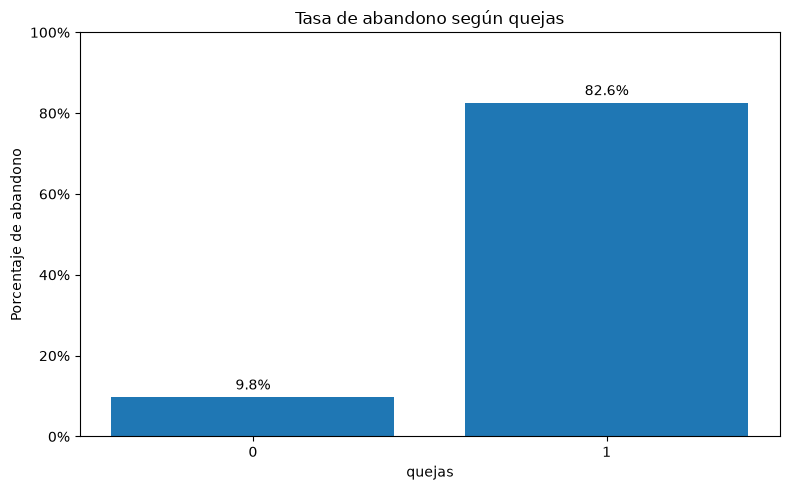

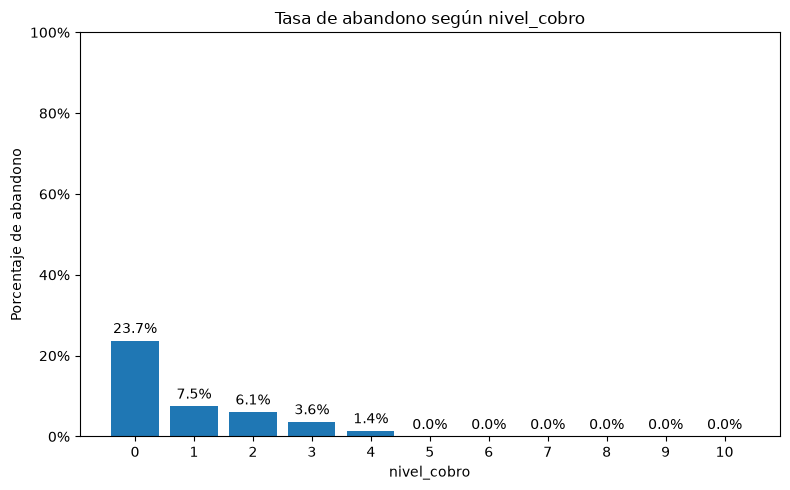

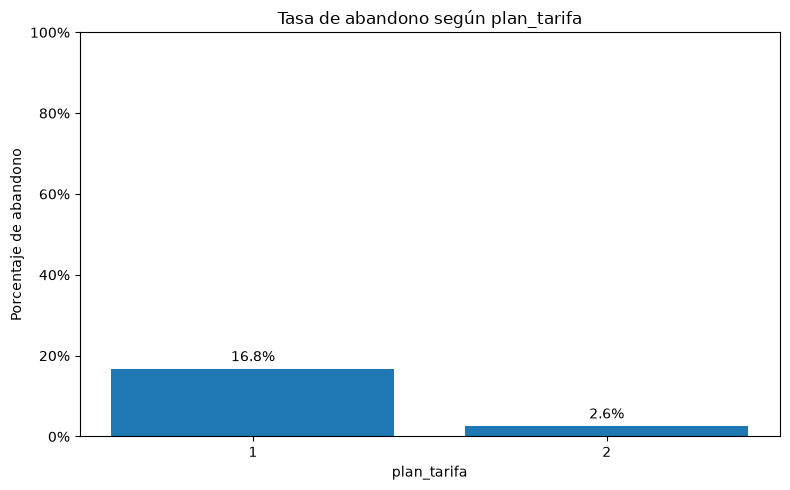

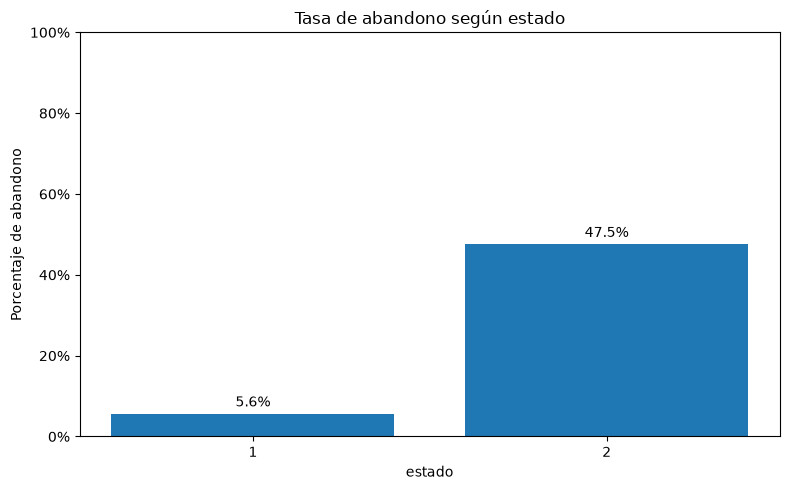

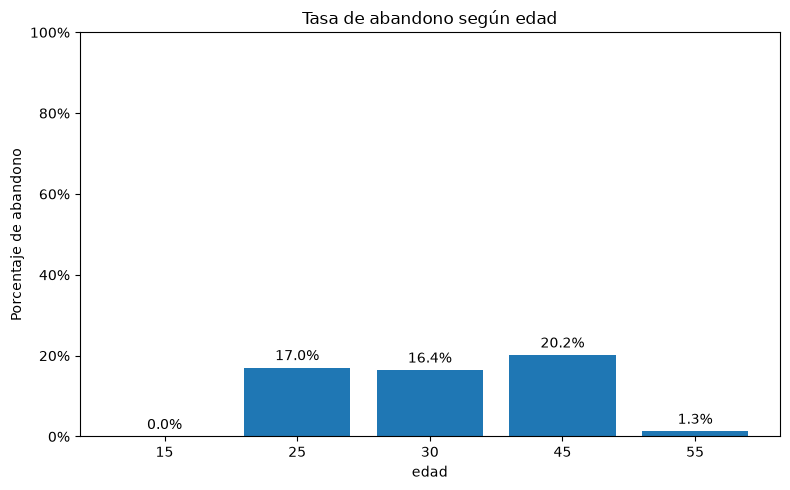

In [6]:
graficar_categoricas(tabla_cat)

In [ ]:
display(tabla_num.to_string(index=False))

'           variable  mediana_abandona  q1_abandona  q3_abandona  mediana_permanece  q1_permanece  q3_permanece      p_valor    efecto\n       segundos_uso          1256.500      438.000      2458.00            3596.50    1858.00000    6920.00000 1.843782e-82 -0.572678\n      valor_cliente           102.565       45.495       187.98             271.54     145.62875     862.59625 1.585944e-79 -0.562160\nfrecuencia_llamadas            29.000        7.000        46.75              64.00      33.00000     106.00000 7.228963e-72 -0.533697\n  numeros_distintos            11.000        3.250        20.00              24.00      13.00000      36.00000 2.413410e-54 -0.462055\n     frecuencia_sms            11.000        1.000        24.00              26.00       7.00000     133.00000 1.966711e-30 -0.340249\n  meses_suscripcion            35.000       31.000        37.00              35.00      29.00000      38.00000 7.770285e-02 -0.052452\n     fallas_llamada             6.000        1.000    

: 